# Data Reading

In [21]:
import pandas as pd

def readFile():
     df = pd.read_csv("E:/1_Eathans/Ethans/Data/Airline/Airline1.csv")
     return df


#  Cleaning

# Source,Destination,Route,Total_Stops,Price


In [22]:
def Handel_Missing(df):
    missin_COL = ['Source','Destination','Route','Total_Stops']
    for i in missin_COL:
        Missing = df[i].mode()[0]
        df.fillna({i:Missing},inplace=True)
        
    Missing_Price = df['Price'].mean()
    df.fillna({'Price':Missing_Price},inplace=True)
    return df


# Handle Duplicates


In [23]:
def Handle_Duplicates(df):
    df.drop_duplicates(inplace=True)
    df[df.duplicated()]
    return df


# Handle unever Values

In [24]:


def Replace_Uneve(df):
    df['Destination'] = df['Destination'].replace({"New Delhi":"Delhi"})
    return df




In [25]:


def convertDur_Min(df):
    for i in df.index:
        ColOne = df.loc[i,'Duration'].split()[0]
        ColTwo = df.loc[i,'Duration'].split()[1]
        
        if "h" in ColOne:
            ColOne = int(ColOne.replace("h",""))*60
        elif "m" in ColOne:
            ColOne = int(ColOne.replace("m",""))

        if "h" in ColTwo:
            ColTwo = int(ColTwo.replace("h",""))*60
        elif "m" in ColTwo:
            ColTwo = int(ColTwo.replace("m",""))
        
        df.loc[i,'DurHrs_Mins'] = ColOne + ColTwo
    return df



In [26]:
def DateTimeConverion(df):
    df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'],format='mixed')
    df['D_day'] = df['Date_of_Journey'].dt.day
    df['D_month'] = df['Date_of_Journey'].dt.month
    df['D_year'] = df['Date_of_Journey'].dt.year
    df['D_hours'] = df['Date_of_Journey'].dt.hour
    df['D_minutes'] = df['Date_of_Journey'].dt.minute

    df['Arrival_Time'] = pd.to_datetime(df['Arrival_Time'],format='mixed')
    df['A_day'] = df['Arrival_Time'].dt.day
    df['A_month'] = df['Arrival_Time'].dt.month
    df['A_year'] = df['Arrival_Time'].dt.year
    df['A_hours'] = df['Arrival_Time'].dt.hour
    df['A_minutes'] = df['Arrival_Time'].dt.minute
    return df


In [27]:
def uncessaryCol(df):
    col_Drop = ['ID','Date_of_Journey','Route','Dep_Time',
                'Arrival_Time','Duration','Additional_Info']
    df.drop(col_Drop,axis=1,inplace=True)
    return df


In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
def remove_Outlier(df):
    df['Airline'].unique()
    airlineName = { 'IndiGo':      [0.25,0.75],
                    "Air India":   [0.27,0.75],
                    'Jet Airways': [0.27,0.75],
                    'SpiceJet':    [0.10,0.60],
                    'Multiple carriers':[0.20,0.80],
                    'GoAir':       [0.20,0.75],
                    'Vistara':     [0.20,0.75],
                    'Air Asia':    [0.25,0.75],
                    'Vistara Premium economy':[0.25,0.75],
                    'Jet Airways Business':[0.25,0.75],
                    'Multiple carriers Premium economy':[0.20,0.75],
                    'Trujet':       [0,0]

                }


    final_df = pd.DataFrame(columns=list(df.columns))
    x=1
    plt.figure(figsize=(15,30))
    for key,value in airlineName.items():
        airDataSet = ""
        airDataSet = df[df['Airline'] == key]

        q1 = airDataSet['Price'].quantile(value[0])
        q3 = airDataSet['Price'].quantile(value[1])
        IQR = q3-q1
        lowerLimit = q1-IQR*1.5
        upperLimit = q3+IQR*1.5
        lowerLimitIndex = airDataSet[airDataSet['Price']<=lowerLimit].index
        upperLimitIndex = airDataSet[airDataSet['Price']>=upperLimit].index

        if airDataSet.shape[0] > 5 : 
            airDataSet.drop(lowerLimitIndex,axis=0,inplace=True)
            airDataSet.drop(upperLimitIndex,axis=0,inplace=True)
        else:
            pass

        df[df.index.isin([2878])]
        #airDataSet1 = airDataSet1.append(airDataSet, ignore_index=True)  # ignore_index=True resets the index
        
        sns.boxplot(airDataSet['Price'])
        plt.subplot(4,4,x)
        plt.show()
        x = x + 1
  
        final_df = pd.concat([final_df, airDataSet], axis=0)  # axis=0 is the default and means appending vertically
        
        df = final_df
        return df


In [29]:
def saveCleanedData(df):
    file_Path = "Airtifacts/Clnd_Data/Cleaned_Data.csv"
    df.to_csv(file_Path,index=False)


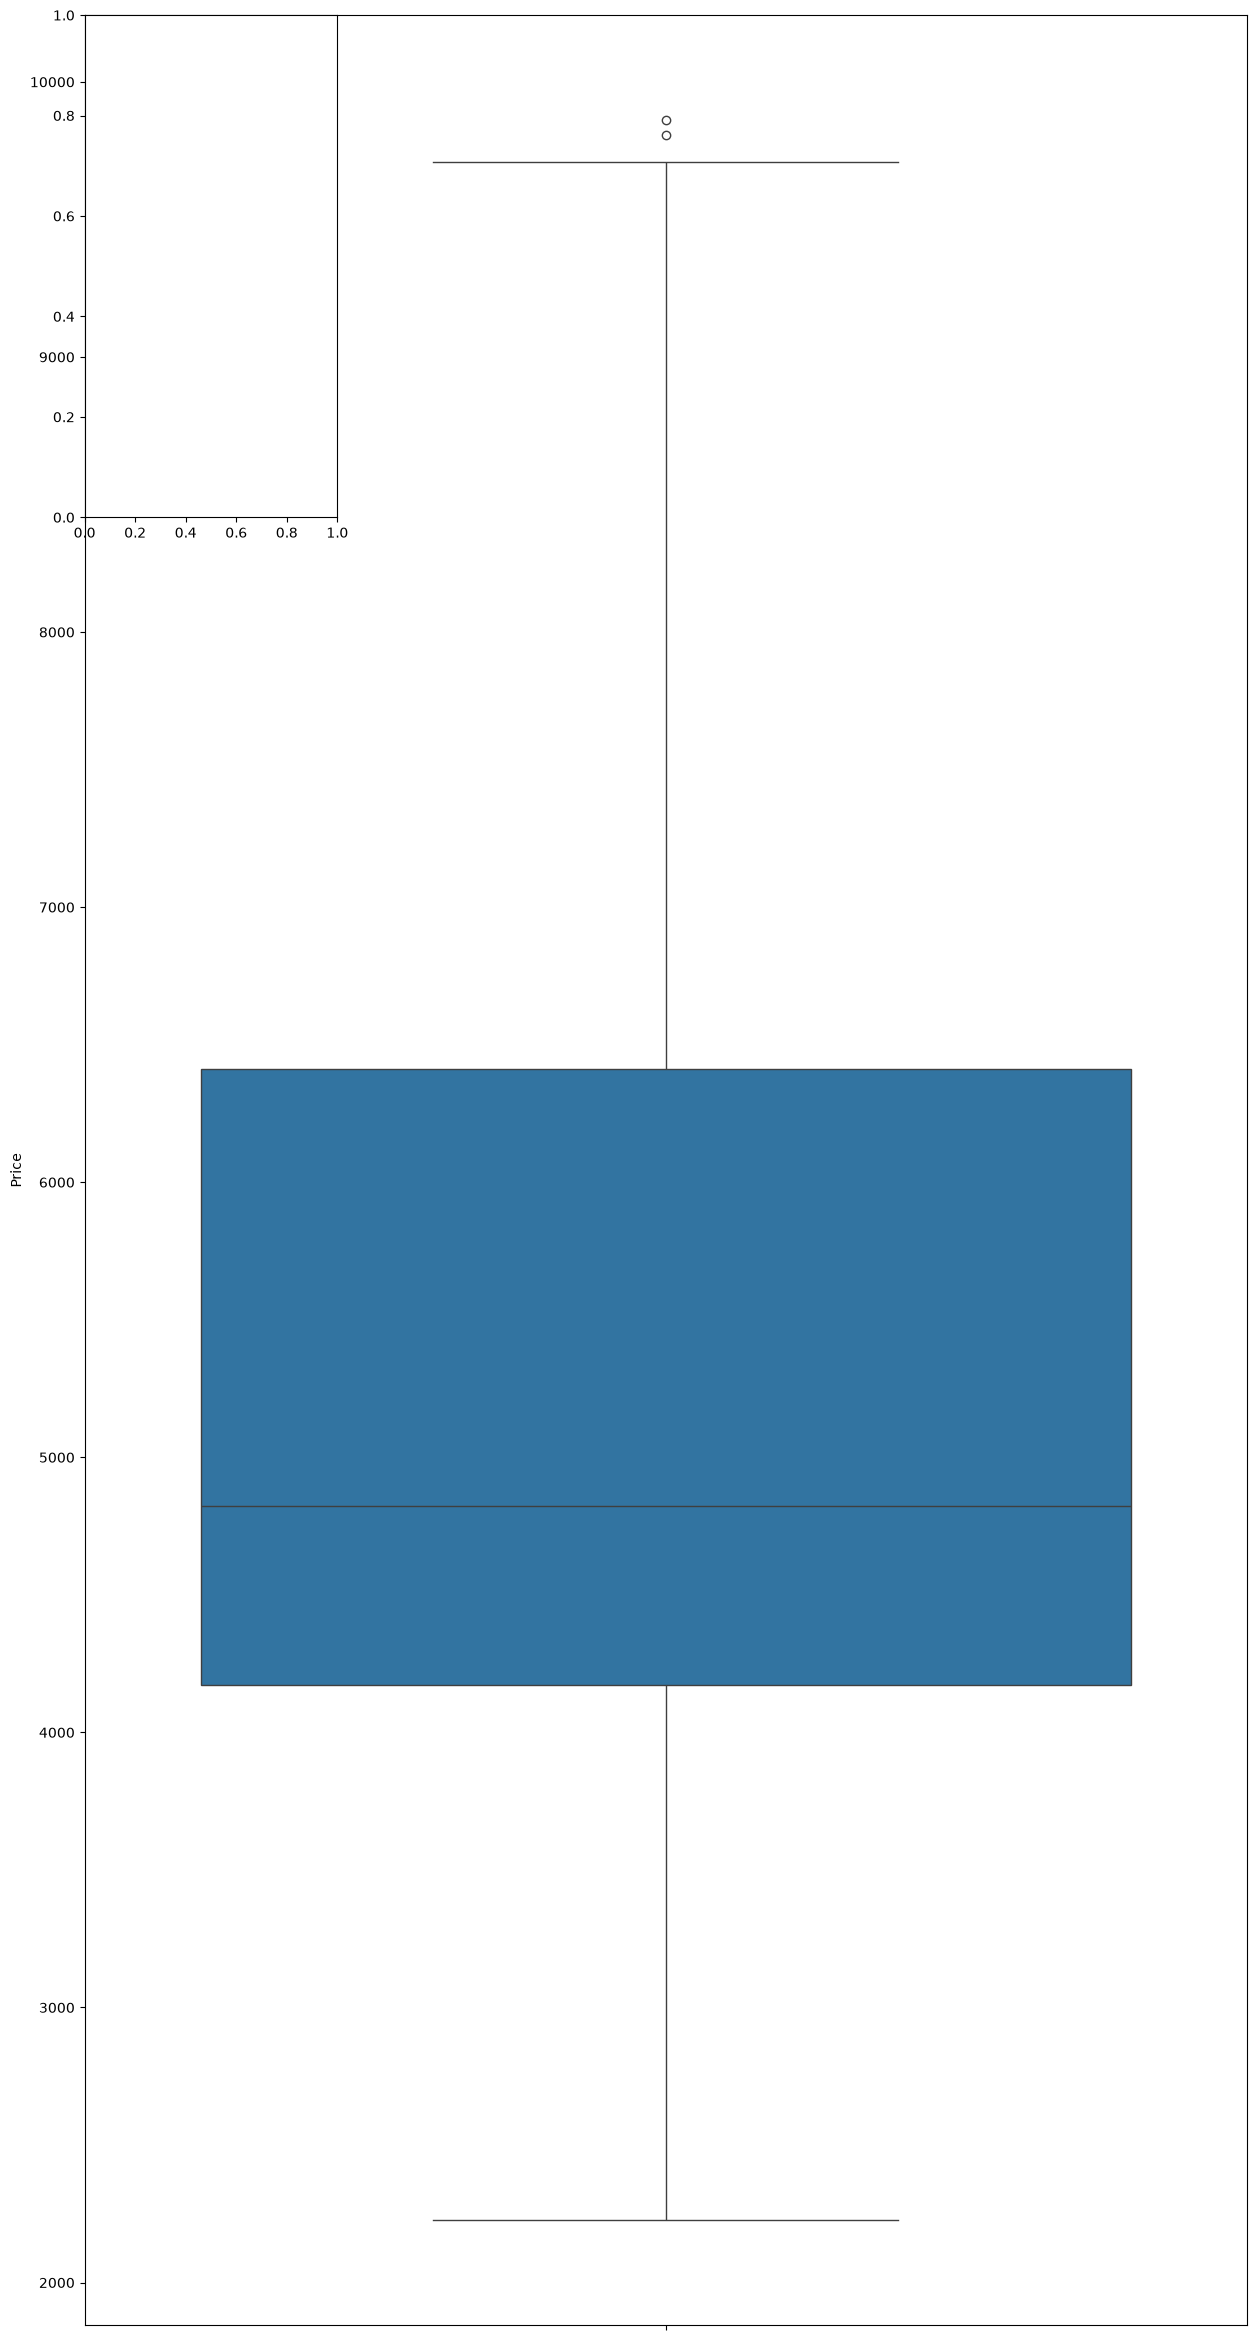

In [30]:
df = readFile()
df = Handel_Missing(df)
df = Handle_Duplicates(df)
df = Replace_Uneve(df)
df = convertDur_Min(df)
df = DateTimeConverion(df)

df = uncessaryCol(df)
df = remove_Outlier(df)

# df = saveCleanedData(df)
#df
